# 01 — Data Understanding
**Workforce Pulse · Phase 1 · HR Attrition & Retention Insights**

**Objective.** Understand the IBM HR dataset *before* writing any transformation or modeling code:
its structure, data quality, target balance and the business meaning of every column.

**Business context (simulation).** We act as a Data Analyst in a People Data & Systems team.
HR management wants to understand attrition and explore retention strategies
(see `docs/business_requirements.md`, questions Q1–Q7).

> ⚠️ The IBM dataset is **fictional**, created by IBM data scientists for demonstration. Nothing here
> describes the behaviour of a real workforce.

**Outputs of this notebook**
- Dataset profile (shape, types, missing, duplicates, cardinality)
- Target distribution and the "accuracy trap" baseline
- Constant / identifier / protected column detection
- Domain validity and logical consistency checks
- `reports/data_quality_table.csv` → basis for `reports/data_quality_report.md`

## 0. Setup

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
from src.data_dictionary import COLUMNS, ORDINAL_LABELS, PROTECTED, TARGET, ID_COL

RAW_PATH = PROJECT_ROOT / "data" / "raw" / "WA_Fn-UseC_-HR-Employee-Attrition.csv"
FIG_DIR = PROJECT_ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")
print("Project root:", PROJECT_ROOT)

Project root: C:\Users\HUAWEI\Documents\workforce-pulse


## 1. Load the CSV
The file starts with a UTF-8 byte-order mark (BOM). Reading it with plain `utf-8` would silently rename
the first column to `\ufeffAge`, so we use `utf-8-sig`. This is a small but real data-ingestion detail.

In [2]:
df = pd.read_csv(RAW_PATH, encoding="utf-8-sig")
assert df.columns[0] == "Age", f"Unexpected first column: {df.columns[0]!r}"
print("Loaded:", RAW_PATH.name)

Loaded: WA_Fn-UseC_-HR-Employee-Attrition.csv


## 2. First and last records

In [3]:
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Y,Yes,11,3,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,Y,No,23,4,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Y,Yes,15,3,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Y,Yes,11,3,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,Y,No,12,3,4,80,1,6,3,3,2,2,2,2


In [4]:
df.tail()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
1465,36,No,Travel_Frequently,884,Research & Development,23,2,Medical,1,2061,3,Male,41,4,2,Laboratory Technician,4,Married,2571,12290,4,Y,No,17,3,3,80,1,17,3,3,5,2,0,3
1466,39,No,Travel_Rarely,613,Research & Development,6,1,Medical,1,2062,4,Male,42,2,3,Healthcare Representative,1,Married,9991,21457,4,Y,No,15,3,1,80,1,9,5,3,7,7,1,7
1467,27,No,Travel_Rarely,155,Research & Development,4,3,Life Sciences,1,2064,2,Male,87,4,2,Manufacturing Director,2,Married,6142,5174,1,Y,Yes,20,4,2,80,1,6,0,3,6,2,0,3
1468,49,No,Travel_Frequently,1023,Sales,2,3,Medical,1,2065,4,Male,63,2,2,Sales Executive,2,Married,5390,13243,2,Y,No,14,3,4,80,0,17,3,2,9,6,0,8
1469,34,No,Travel_Rarely,628,Research & Development,8,3,Medical,1,2068,2,Male,82,4,2,Laboratory Technician,3,Married,4404,10228,2,Y,No,12,3,1,80,0,6,3,4,4,3,1,2


## 3. Dimensions
Expected from the documentation: **1,470 rows × 35 columns**.

In [5]:
n_rows, n_cols = df.shape
print(f"Rows: {n_rows:,}  |  Columns: {n_cols}")
assert (n_rows, n_cols) == (1470, 35), "Dataset does not match the documented shape"

Rows: 1,470  |  Columns: 35


## 4. Numerical vs categorical columns
Note: several *numeric* columns are actually **ordinal survey scales** (1–4 or 1–5), e.g. `JobSatisfaction`.
Storing them as integers is fine, but we must not interpret their distances as exact quantities.

In [6]:
cat_cols = df.select_dtypes(include=["object", "string"]).columns.tolist()
num_cols = df.select_dtypes(include="number").columns.tolist()
ord_cols = list(ORDINAL_LABELS)
print(f"Categorical ({len(cat_cols)}):", cat_cols)
print(f"\nNumerical ({len(num_cols)}):", num_cols)
print(f"\n  of which documented ordinal scales ({len(ord_cols)}):", ord_cols)

Categorical (9): ['Attrition', 'BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'Over18', 'OverTime']

Numerical (26): ['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

  of which documented ordinal scales (7): ['Education', 'EnvironmentSatisfaction', 'JobInvolvement', 'JobSatisfaction', 'RelationshipSatisfaction', 'PerformanceRating', 'WorkLifeBalance']


## 5. Data types

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInvolvement            1470 non-null   int64
 14  JobLevel                  1470 non-null   int64
 15

In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,1470.0,36.923810,9.135373,18.0,30.00,36.0,43.00,60.0
DailyRate,1470.0,802.485714,403.509100,102.0,465.00,802.0,1157.00,1499.0
DistanceFromHome,1470.0,9.192517,8.106864,1.0,2.00,7.0,14.00,29.0
Education,1470.0,2.912925,1.024165,1.0,2.00,3.0,4.00,5.0
EmployeeCount,1470.0,1.000000,0.000000,1.0,1.00,1.0,1.00,1.0
EmployeeNumber,1470.0,1024.865306,602.024335,1.0,491.25,1020.5,1555.75,2068.0
EnvironmentSatisfaction,1470.0,2.721769,1.093082,1.0,2.00,3.0,4.00,4.0
HourlyRate,1470.0,65.891156,20.329428,30.0,48.00,66.0,83.75,100.0
JobInvolvement,1470.0,2.729932,0.711561,1.0,2.00,3.0,3.00,4.0
JobLevel,1470.0,2.063946,1.106940,1.0,1.00,2.0,3.00,5.0


In [9]:
df.describe(include=['object', 'string']).T

,count,unique,top,freq
Attrition,1470,2,No,1233
BusinessTravel,1470,3,Travel_Rarely,1043
Department,1470,3,Research & Development,961
EducationField,1470,6,Life Sciences,606
Gender,1470,2,Male,882
JobRole,1470,9,Sales Executive,326
MaritalStatus,1470,3,Married,673
Over18,1470,1,Y,1470
OverTime,1470,2,No,1054


## 6. Missing values

In [10]:
missing = df.isna().sum()
print("Total missing cells:", int(missing.sum()))
missing[missing > 0]

Total missing cells: 0


Series([], dtype: int64)

In [11]:
# Also check for 'disguised' missing values in text columns (empty strings, 'NA', '?', whitespace)
suspicious = {c: df[c].str.strip().isin(["", "NA", "N/A", "?", "null", "None"]).sum() for c in cat_cols}
{k: int(v) for k, v in suspicious.items() if v > 0} or "No disguised missing values found"

'No disguised missing values found'

## 7. Duplicates
Two checks: fully duplicated rows, and duplicated employee identifiers (a duplicated ID with different values
would be a more serious integrity problem than an exact duplicate row).

In [12]:
print("Fully duplicated rows:          ", int(df.duplicated().sum()))
print("Duplicated EmployeeNumber values:", int(df[ID_COL].duplicated().sum()))
print("Duplicates ignoring the ID column:", int(df.drop(columns=ID_COL).duplicated().sum()))

Fully duplicated rows:           0
Duplicated EmployeeNumber values: 0


Duplicates ignoring the ID column: 0


## 8. Unique values

In [13]:
nunique = df.nunique().sort_values()
nunique.to_frame("n_unique").T

,EmployeeCount,Over18,StandardHours,Attrition,OverTime,PerformanceRating,Gender,BusinessTravel,Department,MaritalStatus,RelationshipSatisfaction,StockOptionLevel,JobSatisfaction,EnvironmentSatisfaction,JobInvolvement,WorkLifeBalance,Education,JobLevel,EducationField,TrainingTimesLastYear,JobRole,NumCompaniesWorked,PercentSalaryHike,YearsSinceLastPromotion,YearsWithCurrManager,YearsInCurrentRole,DistanceFromHome,YearsAtCompany,TotalWorkingYears,Age,HourlyRate,DailyRate,MonthlyIncome,MonthlyRate,EmployeeNumber
n_unique,1,1,1,2,2,2,2,3,3,3,4,4,4,4,4,4,5,5,6,7,9,10,15,16,18,19,29,37,40,43,71,886,1349,1427,1470


In [14]:
for c in cat_cols:
    print(f"{c:15s}", df[c].value_counts().to_dict())

Attrition       {'No': 1233, 'Yes': 237}
BusinessTravel  {'Travel_Rarely': 1043, 'Travel_Frequently': 277, 'Non-Travel': 150}
Department      {'Research & Development': 961, 'Sales': 446, 'Human Resources': 63}
EducationField  {'Life Sciences': 606, 'Medical': 464, 'Marketing': 159, 'Technical Degree': 132, 'Other': 82, 'Human Resources': 27}
Gender          {'Male': 882, 'Female': 588}
JobRole         {'Sales Executive': 326, 'Research Scientist': 292, 'Laboratory Technician': 259, 'Manufacturing Director': 145, 'Healthcare Representative': 131, 'Manager': 102, 'Sales Representative': 83, 'Research Director': 80, 'Human Resources': 52}
MaritalStatus   {'Married': 673, 'Single': 470, 'Divorced': 327}
Over18          {'Y': 1470}
OverTime        {'No': 1054, 'Yes': 416}


## 9. Target distribution
Expected from documentation: 237 Yes / 1,233 No (~16.1%).

**Why this matters.** With a ~16% positive class, a model that predicts *"everyone stays"* is right
~84% of the time while detecting **zero** leavers. That is why accuracy will not be our main metric in Phase 5.

In [15]:
target_counts = df[TARGET].value_counts()
target_pct = df[TARGET].value_counts(normalize=True).mul(100).round(2)
target_summary = pd.DataFrame({"count": target_counts, "percent": target_pct})
display(target_summary)

attrition_rate = (df[TARGET] == "Yes").mean()
print(f"Historical attrition rate:          {attrition_rate:.2%}")
print(f"Majority-class ('No') baseline acc.: {1 - attrition_rate:.2%}  <- accuracy trap")
print(f"No-skill PR-AUC baseline:            {attrition_rate:.3f}")
assert target_counts.to_dict() == {"No": 1233, "Yes": 237}

,count,percent
Attrition,,
No,1233,83.88
Yes,237,16.12


Historical attrition rate:          16.12%
Majority-class ('No') baseline acc.: 83.88%  <- accuracy trap
No-skill PR-AUC baseline:            0.161


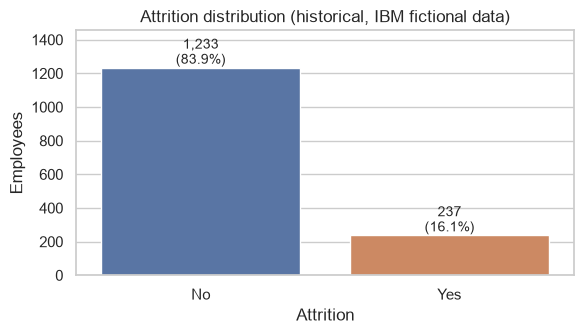

In [16]:
fig, ax = plt.subplots(figsize=(6, 3.5))
order = ["No", "Yes"]
sns.countplot(data=df, x=TARGET, order=order, hue=TARGET, hue_order=order,
              palette=["#4C72B0", "#DD8452"], legend=False, ax=ax)
for p, lab in zip(ax.patches, order):
    ax.annotate(f"{target_counts[lab]:,}\n({target_pct[lab]:.1f}%)",
                (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom", fontsize=10)
ax.set_title("Attrition distribution (historical, IBM fictional data)")
ax.set_xlabel("Attrition"); ax.set_ylabel("Employees")
ax.set_ylim(0, target_counts.max() * 1.18)
plt.tight_layout()
plt.savefig(FIG_DIR / "01_target_distribution.png", dpi=150)
plt.show()

## 10. Constant, identifier and irrelevant variables
We detect these **programmatically** rather than trusting the documentation.

In [17]:
constant_cols = [c for c in df.columns if df[c].nunique(dropna=False) == 1]
id_like_cols = [c for c in df.columns if df[c].nunique() == len(df)]
print("Constant columns:", {c: df[c].iloc[0] for c in constant_cols})
print("Identifier-like columns (unique per row):", id_like_cols)

Constant columns: {'EmployeeCount': np.int64(1), 'Over18': 'Y', 'StandardHours': np.int64(80)}
Identifier-like columns (unique per row): ['EmployeeNumber']


In [18]:
# Near-constant: a single value dominates. Not automatically excluded, but worth noting.
dominance = df.apply(lambda s: s.value_counts(normalize=True).iloc[0])
dominance[(dominance >= 0.80) & (dominance < 1)].sort_values(ascending=False).round(3).to_frame("top_value_share")

,top_value_share
PerformanceRating,0.846
Attrition,0.839


In [19]:
# PerformanceRating is documented on a 1-4 scale. Which values are actually used?
df["PerformanceRating"].value_counts().sort_index()

PerformanceRating
3    1244
4     226
Name: count, dtype: int64

## 11. Domain validity
Ordinal scales must stay within their documented ranges, and numeric values should be plausible.

In [20]:
domain_issues = {}
for col, labels in ORDINAL_LABELS.items():
    bad = ~df[col].isin(labels.keys())
    if bad.any():
        domain_issues[col] = int(bad.sum())
print("Out-of-range ordinal values:", domain_issues or "none")

non_negative = ["DistanceFromHome", "MonthlyIncome", "NumCompaniesWorked", "TotalWorkingYears",
                "TrainingTimesLastYear", "YearsAtCompany", "YearsInCurrentRole",
                "YearsSinceLastPromotion", "YearsWithCurrManager", "PercentSalaryHike"]
print("Negative values:", {c: int((df[c] < 0).sum()) for c in non_negative if (df[c] < 0).any()} or "none")
print("Age range:", df["Age"].min(), "-", df["Age"].max())

Out-of-range ordinal values: none
Negative values: none
Age range: 18 - 60


## 12. Logical consistency between tenure variables
Business rules that must hold in a coherent HR record:
1. `YearsInCurrentRole ≤ YearsAtCompany`
2. `YearsWithCurrManager ≤ YearsAtCompany`
3. `YearsSinceLastPromotion ≤ YearsAtCompany`
4. `YearsAtCompany ≤ TotalWorkingYears`
5. `Age − TotalWorkingYears ≥ 14` (plausible working start age)

In [21]:
rules = {
    "YearsInCurrentRole <= YearsAtCompany": df.YearsInCurrentRole <= df.YearsAtCompany,
    "YearsWithCurrManager <= YearsAtCompany": df.YearsWithCurrManager <= df.YearsAtCompany,
    "YearsSinceLastPromotion <= YearsAtCompany": df.YearsSinceLastPromotion <= df.YearsAtCompany,
    "YearsAtCompany <= TotalWorkingYears": df.YearsAtCompany <= df.TotalWorkingYears,
    "Age - TotalWorkingYears >= 14": (df.Age - df.TotalWorkingYears) >= 14,
}
consistency = pd.DataFrame({"violations": {k: int((~v).sum()) for k, v in rules.items()}})
consistency

,violations
YearsInCurrentRole <= YearsAtCompany,0
YearsWithCurrManager <= YearsAtCompany,0
YearsSinceLastPromotion <= YearsAtCompany,0
YearsAtCompany <= TotalWorkingYears,0
Age - TotalWorkingYears >= 14,0


In [22]:
# NumCompaniesWorked = 0 while TotalWorkingYears > YearsAtCompany is a known ambiguity in this dataset:
# does 0 mean "this is the first employer" or is it a coding quirk? We document, we don't 'fix'.
ambiguous = df[(df.NumCompaniesWorked == 0) & (df.TotalWorkingYears > df.YearsAtCompany)]
print("NumCompaniesWorked==0 but prior experience exists:", len(ambiguous))

NumCompaniesWorked==0 but prior experience exists: 197


## 13. Undocumented compensation columns
`DailyRate`, `HourlyRate` and `MonthlyRate` have no documented definition. If they were genuine pay measures,
they should correlate with `MonthlyIncome` and `JobLevel`. We test that before deciding whether they belong in the model.

In [23]:
comp = ["MonthlyIncome", "DailyRate", "HourlyRate", "MonthlyRate", "JobLevel", "TotalWorkingYears"]
corr_comp = df[comp].corr(method="spearman").round(2)
corr_comp

,MonthlyIncome,DailyRate,HourlyRate,MonthlyRate,JobLevel,TotalWorkingYears
MonthlyIncome,1.00,0.02,-0.02,0.05,0.92,0.71
DailyRate,0.02,1.00,0.02,-0.03,0.00,0.02
HourlyRate,-0.02,0.02,1.00,-0.01,-0.03,-0.01
MonthlyRate,0.05,-0.03,-0.01,1.00,0.05,0.01
JobLevel,0.92,0.00,-0.03,0.05,1.00,0.73
TotalWorkingYears,0.71,0.02,-0.01,0.01,0.73,1.00


## 14. Redundancy check among numeric columns
Highly correlated pairs (|Spearman ρ| ≥ 0.7) matter for Logistic Regression coefficients and for
interpreting feature importance later. This is a *flag*, not an exclusion rule.

In [24]:
num_feat = [c for c in num_cols if c not in constant_cols + [ID_COL]]
corr = df[num_feat].corr(method="spearman")
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
         .rename("rho").reset_index().rename(columns={"level_0": "var_1", "level_1": "var_2"}))
high_corr = pairs[pairs.rho.abs() >= 0.7].sort_values("rho", key=abs, ascending=False).round(3)
high_corr

,var_1,var_2,rho
170,JobLevel,MonthlyIncome,0.920
457,YearsAtCompany,YearsInCurrentRole,0.854
459,YearsAtCompany,YearsWithCurrManager,0.843
177,JobLevel,TotalWorkingYears,0.735
482,YearsInCurrentRole,YearsWithCurrManager,0.725
223,MonthlyIncome,TotalWorkingYears,0.710


## 15. Protected attributes and proxy risk
`Age`, `Gender` and `MaritalStatus` are excluded from model features. But removing them does not remove their
information if other features **encode** them. Quick screen: how strongly does each retained numeric feature relate to Age?

In [25]:
age_proxy = (df[num_feat].corrwith(df["Age"], method="spearman").drop("Age")
             .sort_values(key=abs, ascending=False).round(3).head(6).to_frame("rho_with_Age"))
age_proxy

,rho_with_Age
TotalWorkingYears,0.657
JobLevel,0.490
MonthlyIncome,0.472
NumCompaniesWorked,0.353
YearsAtCompany,0.252
Education,0.205


In [26]:
# Protected-group sizes: small groups produce unstable fairness estimates in Phase 6.
for c in ["Gender", "MaritalStatus"]:
    display(pd.crosstab(df[c], df[TARGET], margins=True))

Attrition,No,Yes,All
Gender,,,
Female,501,87,588
Male,732,150,882
All,1233,237,1470


Attrition,No,Yes,All
MaritalStatus,,,
Divorced,294,33,327
Married,589,84,673
Single,350,120,470
All,1233,237,1470


## 16. Business categorization and data quality table
Combines the documented business meaning (`src/data_dictionary.py`) with the measured statistics above.
Exported to `reports/data_quality_table.csv`.

In [27]:
assert set(COLUMNS) == set(df.columns), set(COLUMNS) ^ set(df.columns)

rows = []
for col in df.columns:
    category, meaning, decision, reason = COLUMNS[col]
    s = df[col]
    rows.append({
        "column": col, "category": category, "dtype": str(s.dtype),
        "missing": int(s.isna().sum()), "n_unique": int(s.nunique()),
        "example_values": ", ".join(map(str, s.drop_duplicates().head(4).tolist())),
        "business_meaning": meaning, "decision": decision, "reason": reason,
    })
dq = pd.DataFrame(rows)
dq.to_csv(PROJECT_ROOT / "reports" / "data_quality_table.csv", index=False)
dq

,column,category,dtype,missing,n_unique,example_values,business_meaning,decision,reason
0,Age,Workforce profile,int64,0,43,"41, 49, 37, 33",Employee age in years,Audit only,"Protected attribute: excluded from model, used..."
1,Attrition,Target,str,0,2,"Yes, No",Whether the employee left (Yes/No),Target,"Prediction outcome, kept separate from features"
2,BusinessTravel,Work conditions,str,0,3,"Travel_Rarely, Travel_Frequently, Non-Travel",Travel frequency (Non-Travel / Rarely / Freque...,Retain,Working-condition indicator
3,DailyRate,Compensation,int64,0,886,"1102, 279, 1373, 1392",Daily rate (undocumented definition),Review,Meaning undocumented; check relation to Monthl...
4,Department,Organizational,str,0,3,"Sales, Research & Development, Human Resources",Department (HR / R&D / Sales),Retain,Organizational structure
5,DistanceFromHome,Work conditions,int64,0,29,"1, 8, 2, 3",Distance from home to work (units undocumented),Retain,Commute burden proxy
6,Education,Workforce profile,int64,0,5,"2, 1, 4, 3","Education level, 1=Below College .. 5=Doctor",Retain,Ordinal background attribute
7,EducationField,Workforce profile,str,0,6,"Life Sciences, Other, Medical, Marketing",Field of study,Retain,Background attribute
8,EmployeeCount,Technical,int64,0,1,1,Record count per row,Exclude,Expected constant: carries no information
9,EmployeeNumber,Technical,int64,0,1470,"1, 2, 4, 5",Employee identifier,Key only,"Identifier: join/export key, never a feature"


In [28]:
dq.groupby(['category', 'decision']).size().unstack(fill_value=0)

decision,Audit only,Exclude,Key only,Retain,Review,Target
category,,,,,,
Career development,0,0,0,7,0,0
Compensation,0,0,0,2,3,0
Organizational,0,0,0,3,0,0
Performance,0,0,0,1,1,0
Satisfaction,0,0,0,4,0,0
Target,0,0,0,0,0,1
Technical,0,3,1,0,0,0
Work conditions,0,0,0,4,0,0
Workforce profile,3,0,0,2,0,0


## 17. Summary
The written interpretation of these outputs (what we found, what we decided and why) is in
`reports/data_quality_report.md`. Decisions marked **Review** are settled with evidence in `02_data_preparation.ipynb`.